# Прогнозирование оттока клиентов

**Вопрос:** какие клиенты с высокой вероятностью уйдут и почему?

**Данные:** Telco Customer Churn. Положи файл в `data/telco_churn.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
FIGURES_DIR = "../figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_csv("../data/telco_churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Размер данных:", df.shape)
df.info()
display(df.isna().sum().sort_values(ascending=False).head(10))
print("Дубликаты:", df.duplicated().sum())

Размер данных: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
dtype: int64

Дубликаты: 0


## 1. Целевая переменная

Смотрим, сколько клиентов ушло. Если классов сильно меньше, это несбалансированная классификация, и accuracy будет обманчивой метрикой.

Churn
0    5174
1    1869
Name: count, dtype: int64
Доля ушедших клиентов: 26.5%


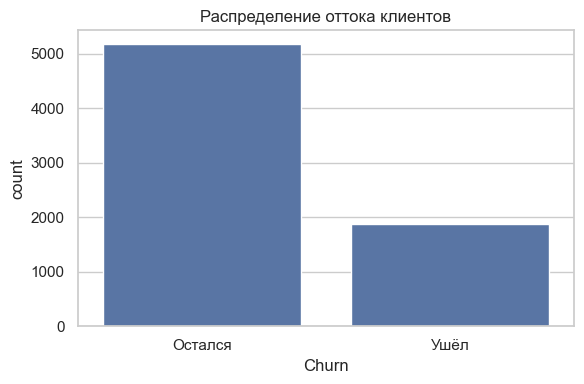

In [3]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

churn_counts = df["Churn"].value_counts()
churn_share = df["Churn"].mean()

print(churn_counts)
print(f"Доля ушедших клиентов: {churn_share:.1%}")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.xticks([0, 1], ["Остался", "Ушёл"])
plt.title("Распределение оттока клиентов")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/churn_distribution.png", dpi=150)
plt.show()

## 2. Очистка данных

`TotalCharges` часто приходит строкой с пробелами. Преобразуем её в число и удалим строки, где значение потерялось.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).copy()

df = df.drop(columns=["customerID"], errors="ignore")

print("После очистки:", df.shape)

После очистки: (7032, 20)


## 3. EDA: кто уходит чаще

Сравниваем отток по типу контракта, сроку обслуживания и ежемесячному платежу.

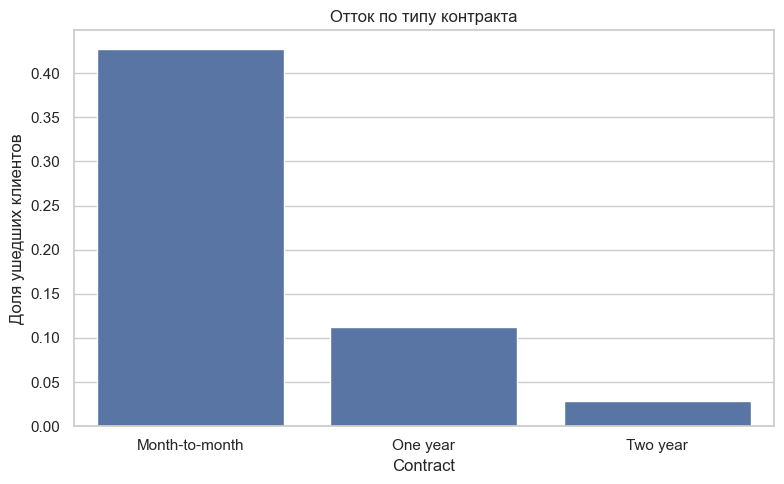

,count,mean
Contract,,
Month-to-month,3875,0.427097
One year,1472,0.112772
Two year,1685,0.028487


In [5]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Contract", y="Churn", errorbar=None)
plt.ylabel("Доля ушедших клиентов")
plt.title("Отток по типу контракта")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/churn_by_contract.png", dpi=150)
plt.show()

df.groupby("Contract")["Churn"].agg(["count", "mean"]).sort_values("mean", ascending=False)

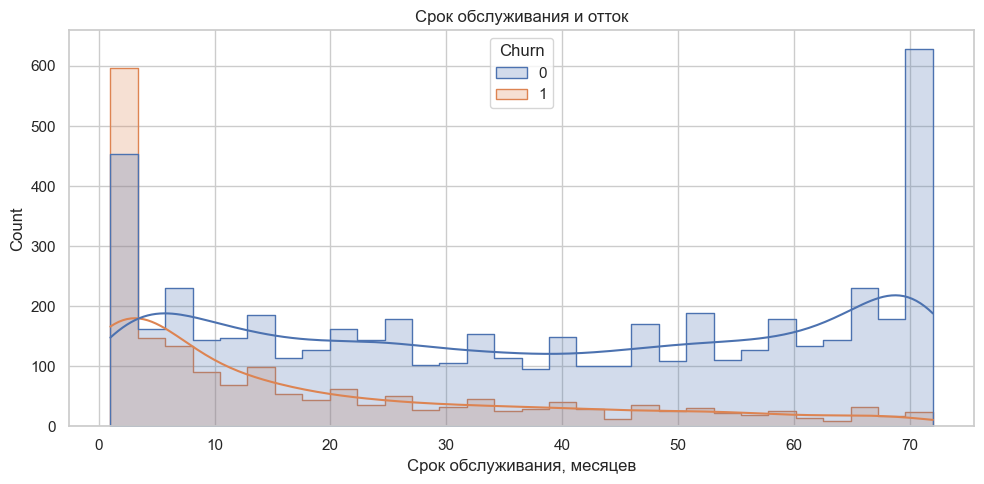

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, element="step")
plt.xlabel("Срок обслуживания, месяцев")
plt.title("Срок обслуживания и отток")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/tenure_vs_churn.png", dpi=150)
plt.show()

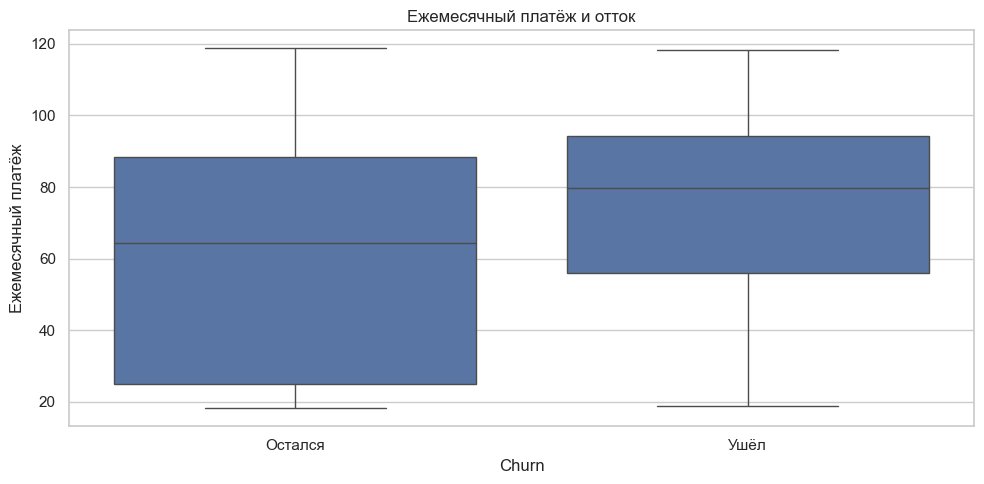

In [7]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.xticks([0, 1], ["Остался", "Ушёл"])
plt.ylabel("Ежемесячный платёж")
plt.title("Ежемесячный платёж и отток")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/monthly_charges_vs_churn.png", dpi=150)
plt.show()

## 4. Подготовка признаков

Кодируем категориальные признаки через one-hot encoding. Числовые признаки масштабируем для логистической регрессии.

In [8]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print(f"Доля оттока в train: {y_train.mean():.1%}")
print(f"Доля оттока в test: {y_test.mean():.1%}")

Обучающая выборка: (5625, 30)
Тестовая выборка: (1407, 30)
Доля оттока в train: 26.6%
Доля оттока в test: 26.6%


## 5. Logistic Regression

Логистическая регрессия — хороший baseline для классификации: быстрая, интерпретируемая и часто не хуже сложных моделей.

In [9]:
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)
log_proba = log_model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, log_pred, target_names=["Остался", "Ушёл"]))
print(f"ROC-AUC: {roc_auc_score(y_test, log_proba):.3f}")

              precision    recall  f1-score   support

     Остался       0.91      0.70      0.79      1033
        Ушёл       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

ROC-AUC: 0.835


## 6. Random Forest

Random Forest ловит нелинейные зависимости и показывает, какие признаки важны для предсказания.

In [10]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred, target_names=["Остался", "Ушёл"]))
print(f"ROC-AUC: {roc_auc_score(y_test, rf_proba):.3f}")

              precision    recall  f1-score   support

     Остался       0.83      0.90      0.86      1033
        Ушёл       0.64      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.820


## 7. Сравнение моделей

Для несбалансированных данных смотрим не только accuracy, но и precision, recall, F1 и ROC-AUC.

In [11]:
def evaluate_model(name, y_true, pred, proba):
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, log_pred, log_proba),
    evaluate_model("Random Forest", y_test, rf_pred, rf_proba)
])

results

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.726368,0.490939,0.796791,0.607543,0.834977
1,Random Forest,0.790334,0.635739,0.494652,0.556391,0.820328


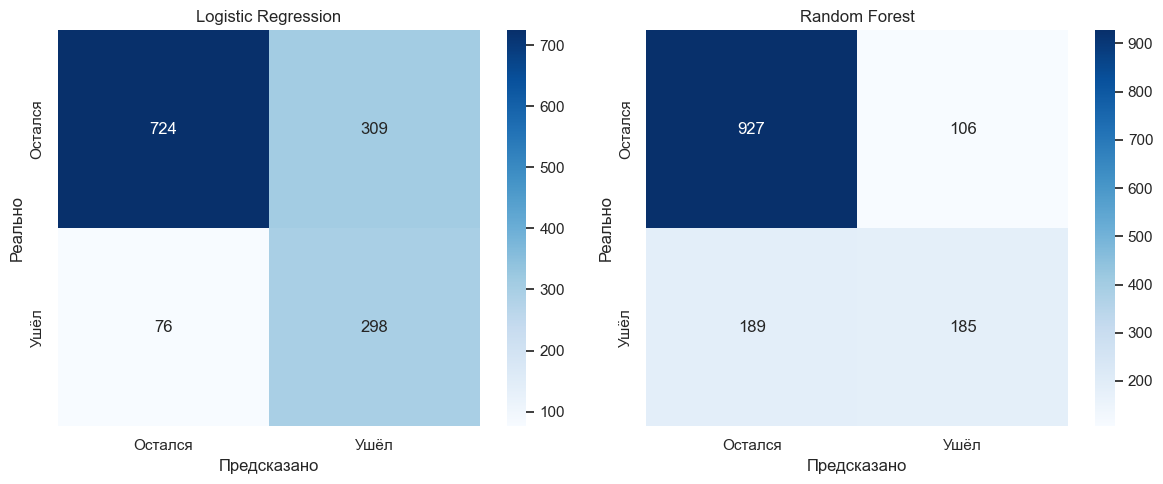

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(
    axes,
    [("Logistic Regression", log_pred), ("Random Forest", rf_pred)]
):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Остался", "Ушёл"],
        yticklabels=["Остался", "Ушёл"]
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("Реально")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/confusion_matrices.png", dpi=150)
plt.show()

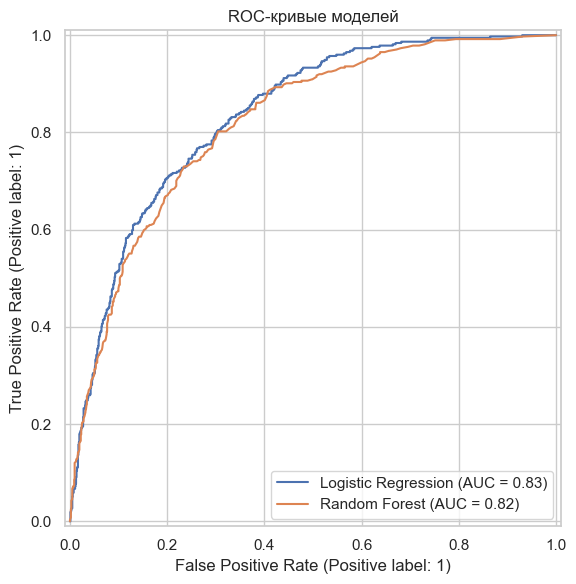

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, log_proba, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, rf_proba, name="Random Forest", ax=ax)
plt.title("ROC-кривые моделей")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/roc_curves.png", dpi=150)
plt.show()

## 8. Важность признаков

Смотрим, какие признаки Random Forest считает наиболее важными. Это не доказывает причинность, но помогает понять модель.

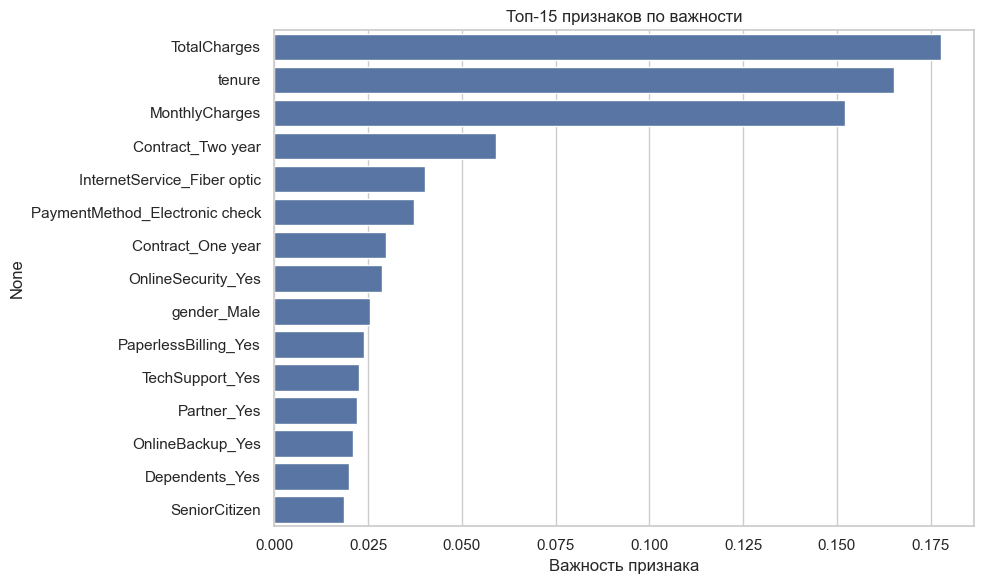

TotalCharges                      0.177709
tenure                            0.165356
MonthlyCharges                    0.152121
Contract_Two year                 0.059161
InternetService_Fiber optic       0.040237
PaymentMethod_Electronic check    0.037347
Contract_One year                 0.029668
OnlineSecurity_Yes                0.028792
gender_Male                       0.025554
PaperlessBilling_Yes              0.023884
TechSupport_Yes                   0.022660
Partner_Yes                       0.022162
OnlineBackup_Yes                  0.021094
Dependents_Yes                    0.019807
SeniorCitizen                     0.018515
dtype: float64

In [14]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=importance.values, y=importance.index)
plt.xlabel("Важность признака")
plt.title("Топ-15 признаков по важности")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/feature_importance.png", dpi=150)
plt.show()

importance

## 9. Сохранение модели для Streamlit

Сохраняем обученную модель, scaler и список колонок, чтобы приложение могло делать предсказания.

In [15]:
import joblib

os.makedirs("../models", exist_ok=True)
joblib.dump(rf_model, "../models/churn_model.joblib")
joblib.dump(list(X_train.columns), "../models/feature_columns.joblib")
print("Модель сохранена в models/churn_model.joblib")

Модель сохранена в models/churn_model.joblib


## 10. Выводы

Заполни после запуска своими числами:

- Доля ушедших клиентов: ...
- Лучшая модель по F1: ...
- ROC-AUC лучшей модели: ...
- Клиенты с каким типом контракта уходят чаще: ...
- Главные факторы оттока: ...

**Важно:** это учебный проект, а не готовое бизнес-решение.